In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
from pyCRLD.Utils import FlowPlot as fp

In [ ]:
# 1st env: Risk-Reward Dilemma

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.9, 
                choice_intensities=20, Rmin=0, Rmax=1,
                method='expectile', tau=0.5, use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


[<Axes: >]

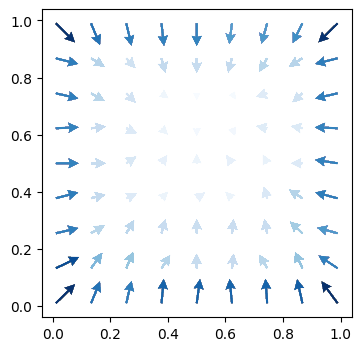

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([0], [1], [0])
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=100, cmap="Blues", axes=ax)

In [ ]:
def expectile(tau, dist, gpoints):
    dim = dist.shape
    dim1 = dist[..., -1].shape
    bdiffs = np.zeros(dim[:-1]+(len(gpoints), len(gpoints)))
    bdiffs = np.repeat(dist[..., np.newaxis], len(gpoints), axis=-1)
    bdiffs = jnp.rot90(bdiffs, 1, axes=(-2, -1))
    xi = jnp.zeros((len(gpoints), len(gpoints)))
    xk = jnp.zeros((len(gpoints), len(gpoints)))
    xi = xi.at[:, :].set(gpoints)
    xk = xk.at[:, :].set(gpoints)
    xk = xk.T
    xdiffs = jnp.zeros(dim[:-1]+(len(gpoints), len(gpoints)))
    adiffs = jnp.abs(xi - xk)
    xdiffs = xdiffs.at[..., :, :].set(adiffs)
    xb = xdiffs * bdiffs
    xb_num = jnp.tril(xb, 0)
    xb_den = jnp.triu(xb, 0)
    candidates = jnp.sum(xb_num[..., :-1, :], axis=-1) / jnp.sum(xb_den[..., :-1, :], axis=-1)
    edist0 = np.ones(dim1) * -1
    edist = jnp.ones(dim1) * -1
    mask = candidates < tau / (1 - tau)
    eidx = jnp.sum(mask, axis=-1)
    for index, _ in np.ndenumerate(edist0):
        idx = eidx[index] - 1
        edist = edist.at[index].set((gpoints[idx] + gpoints[idx+1]) / 2)
    return edist

In [ ]:
X = 0.5 * jnp.ones((1, 2, 2))
Qval = db.Qisaq(X)

In [ ]:
Qval[0, 0, 0]

Array([0.0087408 , 0.01310258, 0.02117629, 0.02888433, 0.03607335,
       0.0428491 , 0.04902545, 0.05445663, 0.0591145 , 0.06296986,
       0.06592868, 0.06781784, 0.06839865, 0.06741201, 0.06465398,
       0.0600634 , 0.05379283, 0.04623264, 0.03796985, 0.0296845 ,
       0.02201652, 0.01544611, 0.01022451, 0.00637256, 0.0037347 ,
       0.00205688, 0.00105701, 0.00048898, 0.00025577], dtype=float32)

In [ ]:
Qval.shape

(1, 2, 2, 29)